# Task 2 - Random Forest random search

This notebook searches for the best Random Forest hyperparameters using stratified cross-validation on the training partition. The search maximises Normal-class precision, matching the existing Random Forest classification notebook, and evaluates the selected model once on the held-out validation partition.

The search includes:

- `n_estimators`: 50-300;
- `max_depth`: 5-20;
- `min_samples_leaf`: 1-8;
- `criterion`: Gini, entropy, and log loss;
- `min_samples_split`: 5-20.


In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],
    "font.size": 8,           # Matches ootnotesize
    "axes.labelsize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "figure.titlesize": 9
})
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score, make_scorer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split

RANDOM_STATE = 12
TEST_SIZE = 0.20
CV_SPLITS = 5
N_ITER = 30
SNR_LEVELS = ["SNR_noiseless", "SNR_50db", "SNR_40db", "SNR_30db", "SNR_20db"]
CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harmonics", "Swell_harmonics", "Transient", "Flicker"]
DISPLAY_CLASS_NAMES = ["Normal", "Sag", "Swell", "Interruption", "Harmonics", "Sag_harm", "Swell_harm", "Transient", "Flicker"]
NORMAL_LABEL = "Normal"
FEATURE_COLUMNS = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8"]
RAW_TO_FEATURE = {"avg abs": "F2", "sd": "F3", "max": "F4", "min": "F5", "no. pks": "F6", "sd fma": "F7", "sd fma 3": "F1", "no. pt near 0": "F8"}

def normal_precision(y_true, y_pred):
    return precision_score(y_true, y_pred, labels=[NORMAL_LABEL], average="macro", zero_division=0)

normal_precision_scorer = make_scorer(normal_precision)


## 1. Load the data and create a stratified train/validation split


In [23]:
def load_feature_data(data_root):
    frames = []
    for snr in SNR_LEVELS:
        snr_dir = data_root / snr
        if not snr_dir.is_dir():
            raise FileNotFoundError(f"Missing SNR directory: {snr_dir}")
        for csv_path in sorted(snr_dir.glob("*.csv")):
            label = csv_path.stem
            if label not in CLASS_NAMES:
                raise ValueError(f"Unexpected class file: {csv_path.name}")
            frame = pd.read_csv(csv_path).rename(columns=RAW_TO_FEATURE)
            missing = set(FEATURE_COLUMNS) - set(frame.columns)
            if missing:
                raise ValueError(f"{csv_path} is missing features: {sorted(missing)}")
            frame = frame[FEATURE_COLUMNS].copy()
            frame["label"] = label
            frame["snr"] = snr.removeprefix("SNR_")
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

current = Path.cwd().resolve()
DATA_ROOT = next((path / "Code" / "data" for path in [current, *current.parents] if (path / "Code" / "data").is_dir()), None)
if DATA_ROOT is None:
    raise FileNotFoundError("Could not find Code/data. Run this notebook inside the project repository.")

dataset = load_feature_data(DATA_ROOT)
X = dataset[FEATURE_COLUMNS]
y = dataset["label"]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print(f"Using data from: {DATA_ROOT}")
print(f"Loaded {len(dataset):,} samples with {X.shape[1]} features.")
print(f"Training samples: {len(X_train):,}; validation samples: {len(X_valid):,}")


Using data from: /Users/felixvossbrink/Library/Mobile Documents/com~apple~CloudDocs/Uni/02 Master/01 Electrical Engineering/05 Quarter/01 Machine Learning/05 Project/EE4C12---Machine-Learning-Project/Code/data
Loaded 6,705 samples with 8 features.
Training samples: 5,364; validation samples: 1,341


## 2. Random search over the Random Forest hyperparameters

`min_samples_split` is sampled from 5 through 20 inclusive. The three supported split criteria are tested: Gini impurity, entropy, and log loss.


In [24]:
RUN_RANDOM_SEARCH = False

PARAM_DISTRIBUTIONS = {
    "n_estimators": list(range(50, 301)),
    "max_depth": list(range(5, 21)),
    "min_samples_leaf": list(range(1, 9)),
    "criterion": ["gini", "entropy", "log_loss"],
    "min_samples_split": list(range(5, 21)),
}

BEST_PARAMS = {
    "n_estimators": 300,
    "max_depth": 19,
    "min_samples_leaf": 1,
    "criterion": "log_loss",
    "min_samples_split": 18,
    "max_features": "sqrt",
}

if RUN_RANDOM_SEARCH:
    random_search = RandomizedSearchCV(
        estimator=RandomForestClassifier(max_features="sqrt", random_state=RANDOM_STATE, n_jobs=-1),
        param_distributions=PARAM_DISTRIBUTIONS,
        n_iter=N_ITER,
        scoring={
            "normal_precision": normal_precision_scorer,
            "accuracy": "accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
        },
        refit="normal_precision",
        cv=StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE),
        n_jobs=-1,
        random_state=RANDOM_STATE,
        return_train_score=False,
    )
    random_search.fit(X_train, y_train)
    BEST_PARAMS = random_search.best_params_
    random_results = pd.DataFrame(random_search.cv_results_).sort_values(
        "mean_test_normal_precision", ascending=False
    ).reset_index(drop=True)
    result_columns = [
        "params", "mean_test_normal_precision", "mean_test_accuracy",
        "mean_test_precision_macro", "mean_test_recall_macro", "mean_test_f1_macro",
    ]
    display(random_results[result_columns].head(10))
    print("Best cross-validated Normal precision:", random_search.best_score_)
else:
    print("Skipping random search; using the recorded best parameters.")

print("Selected configuration:", BEST_PARAMS)
final_model = RandomForestClassifier(**BEST_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
final_model.fit(X_train, y_train)


Skipping random search; using the recorded best parameters.
Selected configuration: {'n_estimators': 300, 'max_depth': 19, 'min_samples_leaf': 1, 'criterion': 'log_loss', 'min_samples_split': 18, 'max_features': 'sqrt'}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'log_loss'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",19
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",18
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",12
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the to

## 3. Evaluate the selected Random Forest


,Metric,Value
0,Accuracy,0.982103
1,Normal precision,0.928105
2,Macro precision,0.982320
3,Macro recall,0.982103
4,Macro F1,0.982151
5,Weighted F1,0.982151


,precision,recall,f1-score,support
Normal,0.928105,0.953020,0.940397,149.0
Sag,0.993197,0.979866,0.986486,149.0
Swell,1.000000,1.000000,1.000000,149.0
Interruption,0.980132,0.993289,0.986667,149.0
Harmonics,1.000000,1.000000,1.000000,149.0
Sag_harmonics,1.000000,1.000000,1.000000,149.0
Swell_harmonics,1.000000,1.000000,1.000000,149.0
Transient,0.953333,0.959732,0.956522,149.0
Flicker,0.986111,0.953020,0.969283,149.0


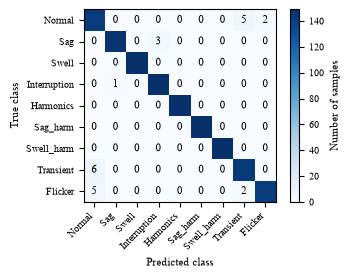

In [25]:
import sys
from matplotlib import figure
from pathlib import Path


# Get the current working directory where the notebook is running
CURRENT_DIR = Path.cwd()
REPOSITORY_ROOT = CURRENT_DIR.parents[2]  # Adjust the index (2) based on your folder depth
sys.path.insert(0, str(CURRENT_DIR))

y_pred = final_model.predict(X_valid)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Normal precision", "Macro precision", "Macro recall", "Macro F1", "Weighted F1"],
    "Value": [
        accuracy_score(y_valid, y_pred),
        normal_precision(y_valid, y_pred),
        precision_score(y_valid, y_pred, average="macro", zero_division=0),
        recall_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="macro", zero_division=0),
        f1_score(y_valid, y_pred, average="weighted", zero_division=0),
    ],
})
display(metrics)

report = pd.DataFrame(classification_report(y_valid, y_pred, labels=CLASS_NAMES, output_dict=True, zero_division=0)).T
display(report.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]])

confusion = confusion_matrix(y_valid, y_pred, labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(3.5, 2.5))
image = ax.imshow(confusion, cmap="Blues")
for row in range(confusion.shape[0]):
    for column in range(confusion.shape[1]):
        if row != column:
            ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set_xticks(range(len(CLASS_NAMES)), DISPLAY_CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(CLASS_NAMES)), DISPLAY_CLASS_NAMES)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
fig.colorbar(image, ax=ax, label="Number of samples")


output_path = REPOSITORY_ROOT / "Paper - IEEE" / "02_Plots" / "random_forest_confusion_matrix.pdf"
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, bbox_inches="tight")
plt.show()